# AeroTrack — Part 3: Person Re-Identification with OSNet

## Objective

Part 1 detects and tracks people. BoT-SORT gives each continuous tracklet a temporary `track_id`. If a person leaves the frame and returns, BoT-SORT may assign a new ID.

Part 3 adds an appearance-based Re-Identification (ReID) layer. It extracts person crops from the tracklets, converts each crop into an OSNet appearance embedding, and compares tracklets that occurred at different times.

**This notebook does not rerun YOLO or BoT-SORT.** It uses the source drone video and the `continuity_track_log.csv` created by Experiment 008.

## What this notebook does

1. Load the Experiment 008 tracking log and original drone video.
2. Select representative, reasonably clear crops from each tracklet.
3. Save and visually inspect the crops.
4. Load a pretrained OSNet model.
5. Extract one appearance embedding per crop.
6. Aggregate crop embeddings into one feature vector per tracklet.
7. Rank possible matches between non-overlapping tracklets.
8. Let a human review candidate matches before merging tracklets into provisional global identities.

## Important limitations

- The pretrained OSNet checkpoint used here was trained on MSMT17, a general pedestrian ReID dataset. It was not trained specifically for overhead drone imagery.
- Person ReID in drone footage is difficult because people can be small, partially occluded, and viewed from different angles or altitudes.
- A high cosine similarity is a candidate match, not proof that two tracklets are the same person.
- This notebook will **not automatically merge identities based on an uncalibrated similarity threshold**. You will review candidate pairs first.
- The resulting `global_id` values are provisional until matches are confirmed.

Research on aerial ReID describes low resolution, occlusion and viewpoint variation as important challenges. Aerial-specific datasets such as PRAI-1581 and P-DESTRE are relevant for later model adaptation.

References:
- OSNet/ReID package: https://github.com/roboflow/re-ID
- Pretrained OSNet checkpoint: https://huggingface.co/kaiyangzhou/osnet
- UAV ReID research: https://openaccess.thecvf.com/content/WACV2024W/RWS/papers/Khaldi_Unsupervised_Person_Re-Identification_in_Aerial_Imagery_WACVW_2024_paper.pdf

## Section 1 — Project paths and settings

Keep this notebook in the existing `AeroTrack` folder.

Place the original video in `data/` and the tracking log from Experiment 008 in `outputs/`.

Expected files:

```text
AeroTrack/
├── data/
│   └── drone_video.mov
├── outputs/
│   └── continuity_track_log.csv
├── runs/
└── AeroTrack_Part3_Person_ReIdentification.ipynb
```

If your filenames are different, update the two settings below.

In [1]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "data"
OUTPUT_DIR = PROJECT_DIR / "outputs"

# Update these names if your files are named differently.
VIDEO_FILENAME = "drone_video.mov"
TRACK_LOG_FILENAME = "continuity_track_log.csv"

VIDEO_PATH = DATA_DIR / VIDEO_FILENAME
TRACK_LOG_PATH = OUTPUT_DIR / TRACK_LOG_FILENAME

# Part 3 output folders.
REID_OUTPUT_DIR = OUTPUT_DIR / "part3_reid"
CROP_DIR = REID_OUTPUT_DIR / "tracklet_crops"

REID_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CROP_DIR.mkdir(parents=True, exist_ok=True)

print("Project folder:", PROJECT_DIR)
print("Video:", VIDEO_PATH, "| Exists:", VIDEO_PATH.exists())
print("Track log:", TRACK_LOG_PATH, "| Exists:", TRACK_LOG_PATH.exists())
print("ReID output folder:", REID_OUTPUT_DIR)

Project folder: c:\Users\anyan\source\repos\AeroTrack
Video: c:\Users\anyan\source\repos\AeroTrack\data\drone_video.mov | Exists: True
Track log: c:\Users\anyan\source\repos\AeroTrack\outputs\continuity_track_log.csv | Exists: True
ReID output folder: c:\Users\anyan\source\repos\AeroTrack\outputs\part3_reid


## Section 2 — Install the ReID library

The `reid` package provides a common interface for loading pretrained OSNet models and extracting embeddings from image crops.

Run this installation cell once. It requires Python 3.10 or newer and depends on PyTorch 2.0 or newer. Your current Python/PyTorch setup should satisfy those declared minimum versions.

This cell does not ask you to reinstall PyTorch or change your CUDA installation. If installation reports a dependency conflict, stop and share the message rather than forcing a PyTorch upgrade.

In [2]:
%pip install reid

Note: you may need to restart the kernel to use updated packages.


## Section 3 — Imports and hardware check

Import the tools used in the notebook and choose CUDA if PyTorch can see your NVIDIA GPU.

In [3]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import time
import math

from PIL import Image
from IPython.display import display

print("PyTorch:", torch.__version__)
print("OpenCV:", cv2.__version__)

if torch.cuda.is_available():
    REID_DEVICE = "cuda"
    print("GPU:", torch.cuda.get_device_name(0))
else:
    REID_DEVICE = "cpu"
    print("CUDA not available. OSNet will use CPU.")

print("ReID device:", REID_DEVICE)

PyTorch: 2.15.0+cu132
OpenCV: 5.1.0
GPU: NVIDIA GeForce RTX 3050 Ti Laptop GPU
ReID device: cuda


## Section 4 — Load and validate the tracking log

The log should contain the following columns:

- `frame`: frame number within the Experiment 008 segment.
- `time_seconds`: time in the original video.
- `track_id`: temporary BoT-SORT identity.
- `confidence`: detector confidence for that observation.
- `x1`, `y1`, `x2`, `y2`: person bounding-box coordinates in the original video frame.

The notebook checks these columns before extracting any crops.

In [4]:
if not VIDEO_PATH.exists():
    raise FileNotFoundError(
        f"Video not found: {VIDEO_PATH}. Check VIDEO_FILENAME."
    )

if not TRACK_LOG_PATH.exists():
    raise FileNotFoundError(
        f"Tracking log not found: {TRACK_LOG_PATH}. "
        "Copy continuity_track_log.csv from Experiment 008 into outputs/."
    )

track_log = pd.read_csv(TRACK_LOG_PATH)

required_columns = {
    "frame", "time_seconds", "track_id",
    "confidence", "x1", "y1", "x2", "y2"
}

missing_columns = required_columns - set(track_log.columns)

if missing_columns:
    raise ValueError(f"Tracking log is missing columns: {missing_columns}")

# Convert the required columns to numeric values.
for column in required_columns:
    track_log[column] = pd.to_numeric(track_log[column], errors="coerce")

track_log = track_log.dropna(subset=list(required_columns)).copy()
track_log["frame"] = track_log["frame"].astype(int)
track_log["track_id"] = track_log["track_id"].astype(int)

print("Tracking observations:", len(track_log))
print("Tracker IDs:", track_log["track_id"].nunique())
print("Frame range:", track_log["frame"].min(), "to", track_log["frame"].max())
print(
    "Time range:",
    round(track_log["time_seconds"].min(), 2),
    "to",
    round(track_log["time_seconds"].max(), 2),
    "seconds"
)

display(track_log.head())

Tracking observations: 7179
Tracker IDs: 54
Frame range: 1 to 899
Time range: 5.03 to 35.0 seconds


,time_seconds,frame,track_id,confidence,x1,y1,x2,y2
0,5.03,1,1,0.875954,804.926514,444.901917,855.760742,554.789978
1,5.03,1,2,0.870182,1948.464844,539.588013,1975.554199,652.721313
2,5.03,1,3,0.865924,1870.552490,536.972778,1899.472168,652.164429
3,5.03,1,4,0.804725,2167.669922,323.597504,2228.581055,400.914398
4,5.03,1,5,0.794399,2195.892578,351.458435,2252.541016,425.664246


## Section 5 — Check video and track-log time alignment

The Experiment 008 log stores a segment-local `frame` number and an original-video `time_seconds` value.

In the Experiment 008 code, time was recorded as:

`time_seconds = segment_start_seconds + frame / source_fps`

We derive the segment start from the CSV instead of assuming it is zero. This is important because the log you shared starts around five seconds into the original video.

The notebook then seeks to that segment start and reads frames sequentially so the bounding-box coordinates are applied to the corresponding video frames.

Check the printed alignment offset. For your Experiment 008 log it should be approximately 5 seconds.

In [5]:
cap = cv2.VideoCapture(str(VIDEO_PATH))

if not cap.isOpened():
    raise RuntimeError("OpenCV could not open the source video.")

SOURCE_FPS = cap.get(cv2.CAP_PROP_FPS)
SOURCE_WIDTH = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
SOURCE_HEIGHT = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

cap.release()

if SOURCE_FPS <= 0:
    raise ValueError("Could not read a valid source-video FPS.")

# Estimate the segment start using the time/frame relationship in the log.
offset_values = (
    track_log["time_seconds"] -
    track_log["frame"] / SOURCE_FPS
)

SEGMENT_START_SECONDS = float(offset_values.median())
OFFSET_DEVIATION = float(
    (offset_values - SEGMENT_START_SECONDS).abs().max()
)

print(f"Video resolution: {SOURCE_WIDTH} x {SOURCE_HEIGHT}")
print(f"Video FPS: {SOURCE_FPS:.3f}")
print(f"Estimated log segment start: {SEGMENT_START_SECONDS:.3f}s")
print(f"Maximum time-mapping deviation: {OFFSET_DEVIATION:.4f}s")

if OFFSET_DEVIATION > 0.10:
    raise ValueError(
        "The frame/time mapping is not consistent with the expected "
        "Experiment 008 format. Check that this CSV belongs to this exact "
        "video and set SEGMENT_START_SECONDS manually if needed."
    )

# If the automatic estimate does not match the segment used in Experiment 008,
# set this to the correct segment start and rerun this cell.
SEGMENT_START_OVERRIDE = None

if SEGMENT_START_OVERRIDE is not None:
    SEGMENT_START_SECONDS = float(SEGMENT_START_OVERRIDE)

print("Segment start used for crop extraction:", SEGMENT_START_SECONDS)

Video resolution: 3840 x 2160
Video FPS: 29.970
Estimated log segment start: 5.000s
Maximum time-mapping deviation: 0.0051s
Segment start used for crop extraction: 4.999933333333334


## Section 6 — Select good observations and representative crops

A tracklet may contain hundreds of detections. We do not need every frame for ReID.

This section:
- Rejects very low-confidence or extremely small boxes.
- Ignores tracklets with too few usable observations.
- Selects up to five crops spread across each tracklet's lifetime.
- Within each time segment, prefers a crop with a higher confidence and larger box.

The filters are only for choosing useful ReID samples. They do not alter the original tracking log.

In [6]:
# Crop-selection settings. These can be adjusted after inspecting the crops.
MIN_CONFIDENCE = 0.25
MIN_BOX_WIDTH = 20
MIN_BOX_HEIGHT = 40
MIN_TRACK_OBSERVATIONS = 5
MAX_CROPS_PER_TRACK = 5
CROP_MARGIN_RATIO = 0.05

# Calculate bounding-box dimensions and a simple crop-quality score.
track_log["box_width"] = track_log["x2"] - track_log["x1"]
track_log["box_height"] = track_log["y2"] - track_log["y1"]
track_log["box_area"] = track_log["box_width"] * track_log["box_height"]

track_log["quality_score"] = (
    track_log["confidence"] * np.sqrt(
        track_log["box_area"].clip(lower=0)
    )
)

# Remove detections that are too small or too uncertain for a first ReID test.
usable_log = track_log[
    (track_log["confidence"] >= MIN_CONFIDENCE) &
    (track_log["box_width"] >= MIN_BOX_WIDTH) &
    (track_log["box_height"] >= MIN_BOX_HEIGHT)
].copy()

# Keep tracklets that have enough usable observations.
usable_counts = usable_log.groupby("track_id").size()
eligible_track_ids = usable_counts[
    usable_counts >= MIN_TRACK_OBSERVATIONS
].index.tolist()

usable_log = usable_log[
    usable_log["track_id"].isin(eligible_track_ids)
].copy()

print("Original tracker IDs:", track_log["track_id"].nunique())
print("Tracker IDs with enough usable observations:", len(eligible_track_ids))
print("Usable detections:", len(usable_log))

# Select up to five temporally spread crops per tracklet.
selected_rows = []

for track_id, group in usable_log.groupby("track_id"):
    group = group.sort_values("frame").reset_index(drop=True)

    number_of_bins = min(MAX_CROPS_PER_TRACK, len(group))

    # Split row positions, then use DataFrame.iloc to get Pandas DataFrames.
    # np.array_split returns NumPy arrays, not DataFrames.
    position_bins = np.array_split(
        np.arange(len(group)),
        number_of_bins
    )

    for sample_number, positions in enumerate(position_bins, start=1):
        if len(positions) == 0:
            continue

        time_bin = group.iloc[positions]

        # Prefer a clearer and larger crop from this time interval.
        best_index = time_bin["quality_score"].idxmax()
        selected = time_bin.loc[best_index].to_dict()
        selected["sample_number"] = sample_number
        selected_rows.append(selected)

selected_crops = pd.DataFrame(selected_rows)

if selected_crops.empty:
    raise ValueError(
        "No representative crops were selected. Try lowering the crop "
        "size/confidence filters or check the tracking log."
    )

print("Representative crops selected:", len(selected_crops))
print("Tracklets represented:", selected_crops["track_id"].nunique())

display(
    selected_crops[
        ["track_id", "frame", "time_seconds", "confidence",
         "box_width", "box_height", "quality_score"]
    ].head(15)
)


Original tracker IDs: 54
Tracker IDs with enough usable observations: 35
Usable detections: 6813
Representative crops selected: 175
Tracklets represented: 35


,track_id,frame,time_seconds,confidence,box_width,box_height,quality_score
0,1.0,50.0,6.67,0.918505,67.386536,105.113770,77.303311
1,1.0,82.0,7.74,0.905379,64.587219,104.217468,74.280345
2,1.0,194.0,11.47,0.917262,61.461975,105.189636,73.753548
3,1.0,223.0,12.44,0.891937,49.927368,105.576141,64.756985
4,1.0,366.0,17.21,0.894420,55.847168,116.975769,72.291944
5,2.0,6.0,5.20,0.871897,27.435913,111.559326,48.236739
6,2.0,236.0,12.87,0.871018,64.106445,99.742920,69.649672
7,2.0,435.0,19.51,0.878805,54.301514,101.208679,65.148936
8,2.0,566.0,23.89,0.895479,42.803223,101.294006,58.963824
9,2.0,693.0,28.12,0.878392,32.814209,90.436359,47.851003


## Section 7 — Extract person crops from the original video

The bounding boxes in the CSV are coordinates in the original 4K frame. This section reads the source video from the log's segment start, crops each selected box, and saves the crops under:

`outputs/part3_reid/tracklet_crops/track_<track_id>/`

A small margin is added around each box to reduce the chance of cutting off a person at the edge of a detection.

In [7]:
# Group selected crop records by their segment-local frame number.
selected_by_frame = {
    int(frame_number): group
    for frame_number, group in selected_crops.groupby("frame")
}

max_local_frame = int(selected_crops["frame"].max())

cap = cv2.VideoCapture(str(VIDEO_PATH))
cap.set(
    cv2.CAP_PROP_POS_MSEC,
    SEGMENT_START_SECONDS * 1000
)

if not cap.isOpened():
    raise RuntimeError("Could not reopen the source video.")

crop_records = []
frames_read = 0
crop_number = 0

while frames_read < max_local_frame:
    success, frame = cap.read()

    if not success:
        break

    frames_read += 1

    # Only process frames that contain selected crops.
    if frames_read not in selected_by_frame:
        continue

    frame_rows = selected_by_frame[frames_read]

    for _, row in frame_rows.iterrows():
        x1, y1, x2, y2 = (
            float(row["x1"]),
            float(row["y1"]),
            float(row["x2"]),
            float(row["y2"])
        )

        box_width = x2 - x1
        box_height = y2 - y1

        # Add a small margin around the person box.
        margin_x = int(box_width * CROP_MARGIN_RATIO)
        margin_y = int(box_height * CROP_MARGIN_RATIO)

        left = max(0, int(x1) - margin_x)
        top = max(0, int(y1) - margin_y)
        right = min(frame.shape[1], int(x2) + margin_x)
        bottom = min(frame.shape[0], int(y2) + margin_y)

        crop = frame[top:bottom, left:right]

        if crop.size == 0:
            continue

        crop_height, crop_width = crop.shape[:2]

        if crop_width < 2 or crop_height < 2:
            continue

        track_id = int(row["track_id"])
        track_folder = CROP_DIR / f"track_{track_id:04d}"
        track_folder.mkdir(parents=True, exist_ok=True)

        crop_name = (
            f"track_{track_id:04d}_"
            f"frame_{frames_read:06d}_"
            f"sample_{int(row['sample_number']):02d}.jpg"
        )
        crop_path = track_folder / crop_name

        # OpenCV writes the BGR crop as a standard image file.
        saved = cv2.imwrite(str(crop_path), crop)

        if not saved:
            continue

        crop_number += 1

        crop_records.append({
            "track_id": track_id,
            "frame": frames_read,
            "time_seconds": float(row["time_seconds"]),
            "confidence": float(row["confidence"]),
            "box_width": crop_width,
            "box_height": crop_height,
            "quality_score": float(row["quality_score"]),
            "crop_path": str(crop_path)
        })

cap.release()

crop_manifest = pd.DataFrame(crop_records)

if crop_manifest.empty:
    raise RuntimeError(
        "No crops were extracted. Check the segment start, source video "
        "and whether the tracking log belongs to this video."
    )

CROP_MANIFEST_PATH = REID_OUTPUT_DIR / "crop_manifest.csv"
crop_manifest.to_csv(CROP_MANIFEST_PATH, index=False)

print("Frames read from segment:", frames_read)
print("Person crops saved:", crop_number)
print("Tracklets with saved crops:", crop_manifest["track_id"].nunique())
print("Crop folder:", CROP_DIR)
print("Crop manifest:", CROP_MANIFEST_PATH)

display(crop_manifest.head(10))

Frames read from segment: 897
Person crops saved: 175
Tracklets with saved crops: 35
Crop folder: c:\Users\anyan\source\repos\AeroTrack\outputs\part3_reid\tracklet_crops
Crop manifest: c:\Users\anyan\source\repos\AeroTrack\outputs\part3_reid\crop_manifest.csv


,track_id,frame,time_seconds,confidence,box_width,box_height,quality_score,crop_path
0,4,3,5.10,0.817081,69,82,56.428308,c:\Users\anyan\source\repos\AeroTrack\outputs\...
1,3,5,5.17,0.870251,32,125,51.028183,c:\Users\anyan\source\repos\AeroTrack\outputs\...
2,2,6,5.20,0.871897,30,121,48.236739,c:\Users\anyan\source\repos\AeroTrack\outputs\...
3,9,7,5.23,0.427551,76,107,35.560644,c:\Users\anyan\source\repos\AeroTrack\outputs\...
4,5,8,5.27,0.855177,61,82,56.542197,c:\Users\anyan\source\repos\AeroTrack\outputs\...
5,9,10,5.33,0.469260,71,107,37.718637,c:\Users\anyan\source\repos\AeroTrack\outputs\...
6,14,10,5.33,0.399978,38,59,17.719295,c:\Users\anyan\source\repos\AeroTrack\outputs\...
7,9,12,5.40,0.312219,69,106,24.555083,c:\Users\anyan\source\repos\AeroTrack\outputs\...
8,9,13,5.43,0.297112,67,102,22.544655,c:\Users\anyan\source\repos\AeroTrack\outputs\...
9,9,14,5.47,0.296107,67,105,22.668347,c:\Users\anyan\source\repos\AeroTrack\outputs\...


## Section 8 — Inspect the extracted crops

This is an important quality check.

OSNet receives each crop resized to its expected input shape. Resizing a very small aerial person does not create new visual detail, so a 20-pixel-wide person may still produce a weak or ambiguous embedding.

Inspect the gallery and look for:
- Crops that contain the full person.
- Crops that mostly contain ground or background.
- Crops that are too small or blurred.
- Incorrectly aligned crops caused by a video/log timing mismatch.

If the crops do not show the correct people, stop here and check the video/CSV pairing and segment start.

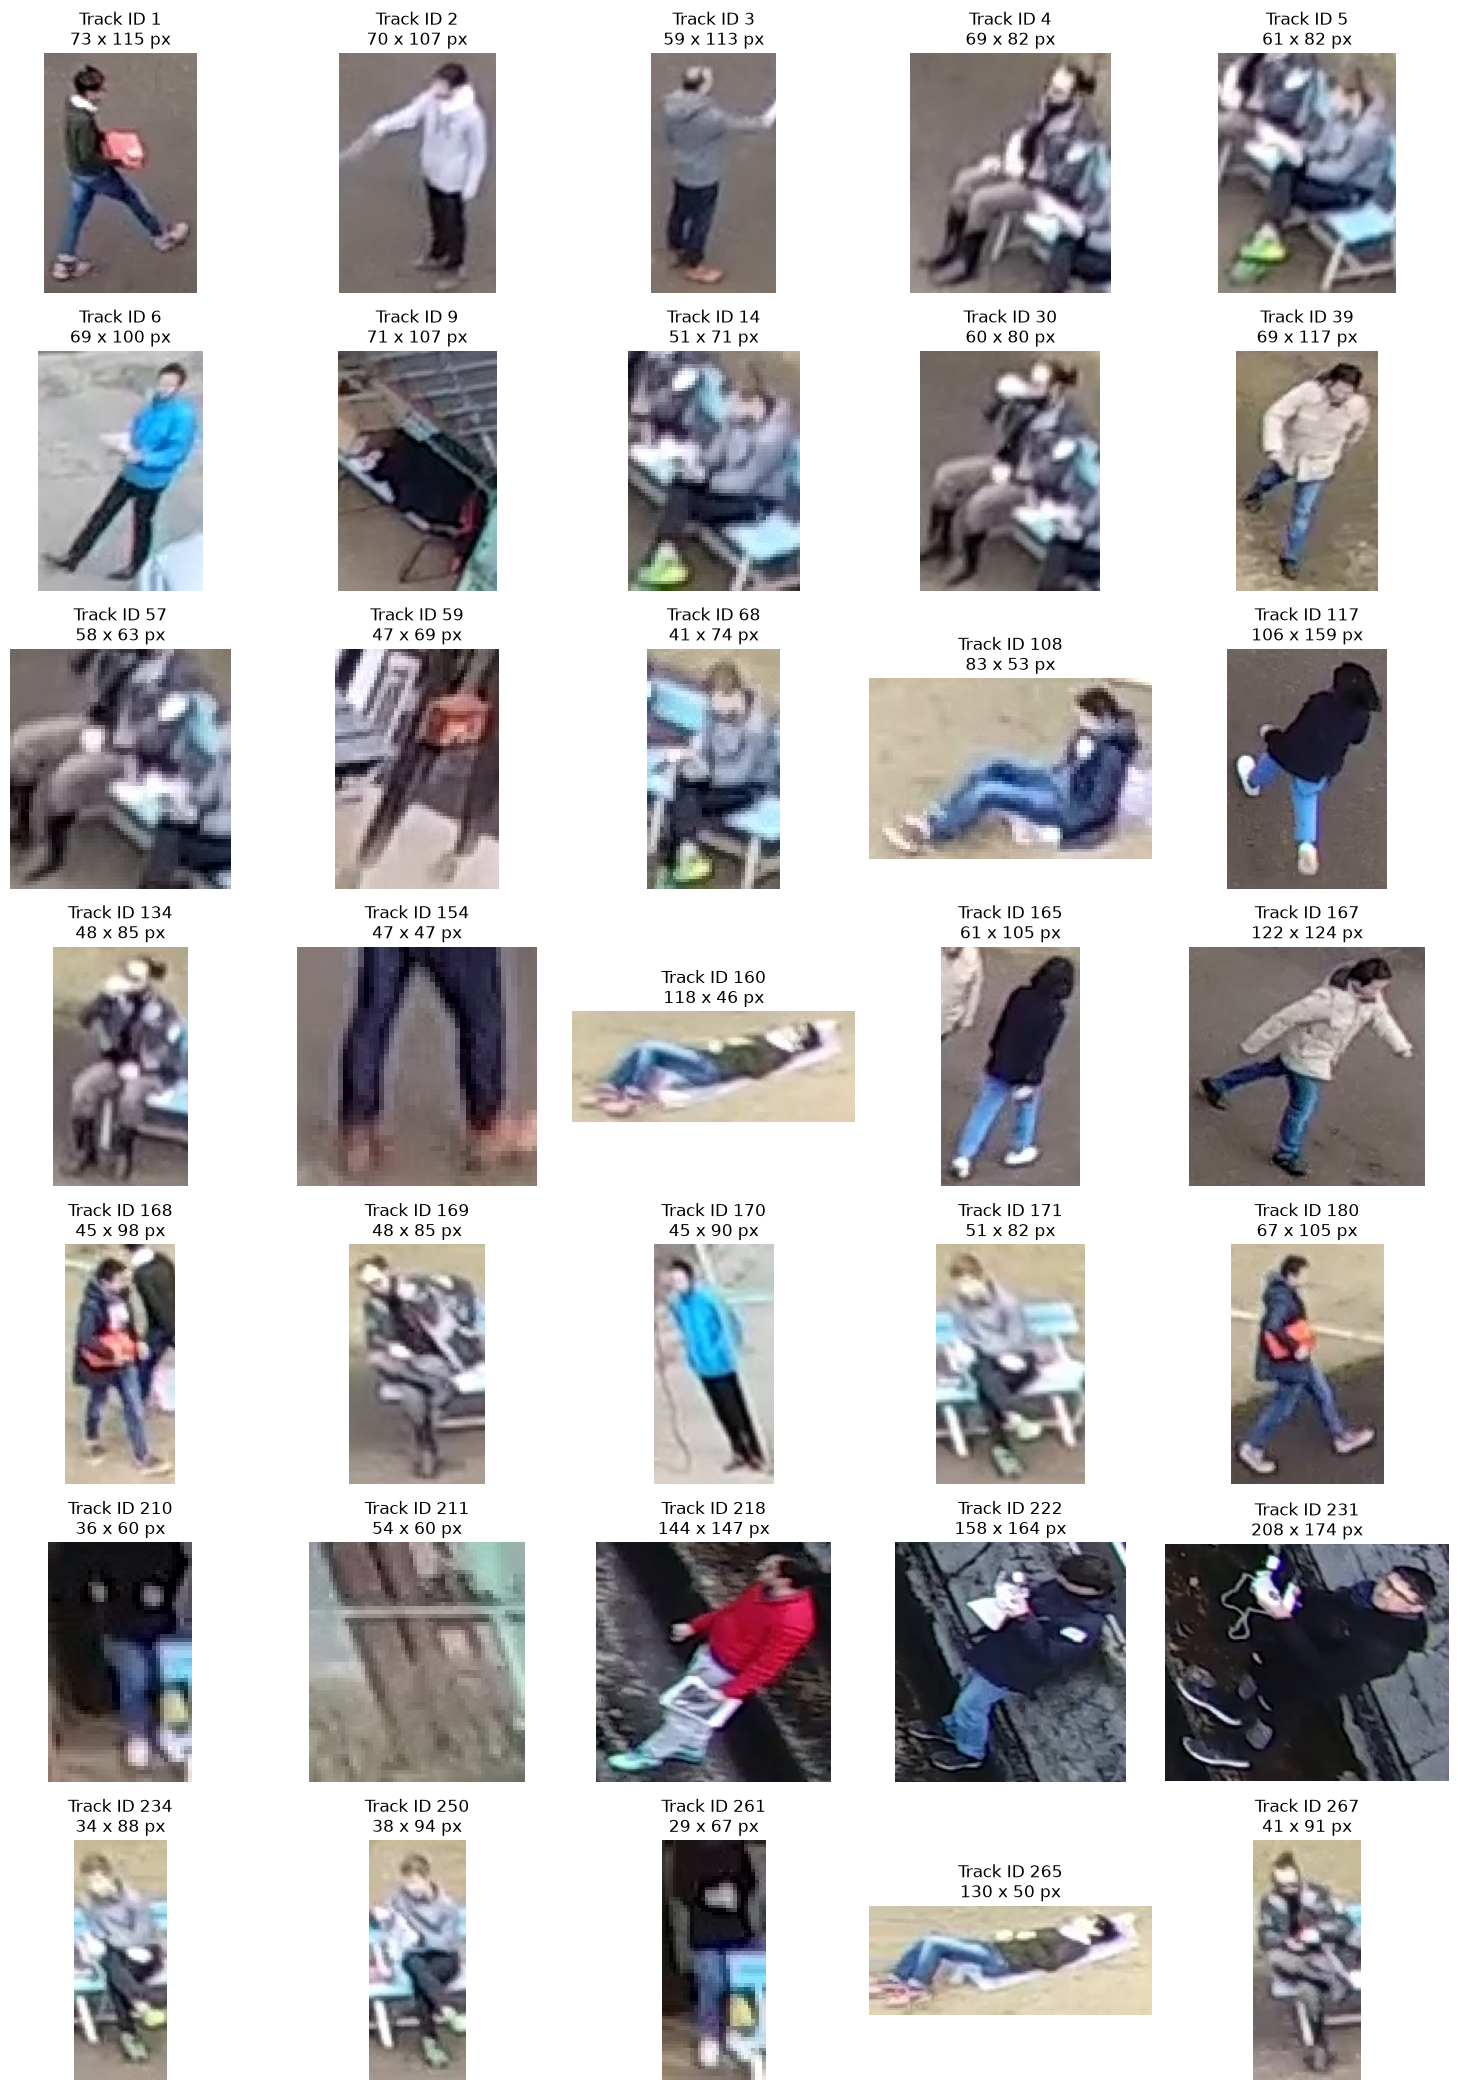

,track_id,crops,mean_confidence,smallest_width,smallest_height
0,1,5,0.905501,54,114
1,2,5,0.879118,30,98
2,3,5,0.878374,32,76
3,4,5,0.725105,55,78
4,5,5,0.791051,31,78
5,6,5,0.858889,32,86
6,9,5,0.360450,67,102
7,14,5,0.448482,37,57
8,30,5,0.723115,52,79
9,39,5,0.900943,63,111


In [8]:
# Choose the clearest crop from each tracklet for a compact gallery.
representative_crops = (
    crop_manifest
    .sort_values("quality_score", ascending=False)
    .drop_duplicates("track_id")
    .sort_values("track_id")
    .reset_index(drop=True)
)

number_of_crops = len(representative_crops)
columns = 5
rows = math.ceil(number_of_crops / columns)

fig, axes = plt.subplots(
    rows, columns,
    figsize=(columns * 3, rows * 3)
)
axes = np.array(axes).reshape(-1)

for ax in axes:
    ax.axis("off")

for index, row in representative_crops.iterrows():
    image = cv2.imread(row["crop_path"])

    if image is None:
        continue

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    axes[index].imshow(image)
    axes[index].set_title(
        f"Track ID {int(row['track_id'])}\n"
        f"{int(row['box_width'])} x {int(row['box_height'])} px"
    )
    axes[index].axis("off")

plt.tight_layout()
plt.show()

# Show crop-size information.
crop_quality_summary = (
    crop_manifest.groupby("track_id")
    .agg(
        crops=("crop_path", "count"),
        mean_confidence=("confidence", "mean"),
        smallest_width=("box_width", "min"),
        smallest_height=("box_height", "min")
    )
    .reset_index()
)

display(crop_quality_summary)

## Section 9 — Load pretrained OSNet

We use the pretrained checkpoint `osnet_x1_0_msmt17_combineall`.

OSNet converts each person crop into a 512-dimensional feature vector (embedding). The package handles the model-specific preprocessing and checkpoint loading.

This checkpoint is trained on MSMT17, not on drone imagery. We are using it as a first baseline to test whether appearance embeddings from your overhead crops contain useful matching information.

In [9]:
from reid import ReIDModel

REID_MODEL_NAME = "osnet_x1_0_msmt17_combineall"

# Load the pretrained OSNet model.
# The weights download automatically on the first run.
reid_model = ReIDModel.from_pretrained(
    REID_MODEL_NAME,
    device=REID_DEVICE
)

print("Loaded ReID model:", REID_MODEL_NAME)
print("Model device:", reid_model.device)
print("Model preprocessing:", reid_model.preprocessing)

C:\Users\anyan\AppData\Local\Temp\ipykernel_11736\893654413.py:7: UserWarning: The osnet_x1_0_msmt17_combineall weights were trained on MSMT17 pedestrian images. Performance may degrade significantly on non-person objects (vehicles, animals, products, etc.). Pass a domain-specific checkpoint via `ReIDModel.from_pretrained(source, architecture=...)` for other use cases.
  reid_model = ReIDModel.from_pretrained(


Loaded ReID model: osnet_x1_0_msmt17_combineall
Model device: cuda
Model preprocessing: ReIDPreprocessing(input_size=(256, 128), mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225), interpolation=<Interpolation.BILINEAR: 'bilinear'>, to_rgb=True, resize_mode='stretch', pad_value=114)


## Section 10 — Extract an embedding from each crop

An embedding is a numerical representation of a person's appearance. The model is trained so that images of the same person tend to have more similar embeddings than images of different people.

The package returns one embedding per saved crop. We will then combine the crops belonging to the same tracklet.

In [10]:
crop_paths = crop_manifest["crop_path"].tolist()

# Use a small batch to keep GPU memory use low.
embedding_start = time.time()

crop_embeddings = reid_model.extract_embeddings_from_paths(
    crop_paths,
    batch_size=8,
    num_workers=0
)

embedding_seconds = time.time() - embedding_start

crop_embeddings = np.asarray(crop_embeddings, dtype=np.float32)

if crop_embeddings.shape[0] != len(crop_manifest):
    raise ValueError(
        "The number of embeddings does not match the number of saved crops."
    )

if not np.isfinite(crop_embeddings).all():
    raise ValueError("The ReID model returned non-finite embeddings.")

print("Crop embeddings shape:", crop_embeddings.shape)
print("Embedding time (seconds):", round(embedding_seconds, 2))
print("Embedding dimensions:", crop_embeddings.shape[1])

Crop embeddings shape: (175, 512)
Embedding time (seconds): 2.21
Embedding dimensions: 512


## Section 11 — Aggregate crop embeddings into tracklet embeddings

A tracklet can have several saved crops from different moments. We first normalize each crop embedding, average the embeddings for the same tracklet, and normalize the average again.

This produces one feature vector per temporary tracker ID.

It is a simple aggregation method for the baseline. Later we can compare it with quality-weighted aggregation or attention-based pooling.

In [11]:
def l2_normalize(vector, axis=-1, epsilon=1e-12):
    norm = np.linalg.norm(vector, axis=axis, keepdims=True)
    return vector / np.maximum(norm, epsilon)


# Normalize every crop embedding before aggregation.
normalized_crop_embeddings = l2_normalize(crop_embeddings)

tracklet_ids = sorted(
    crop_manifest["track_id"].astype(int).unique().tolist()
)

tracklet_embeddings = []
tracklet_rows = []

for track_id in tracklet_ids:
    row_indices = crop_manifest.index[
        crop_manifest["track_id"].astype(int) == track_id
    ].to_numpy()

    # Average the normalized crop embeddings for this tracklet.
    mean_embedding = normalized_crop_embeddings[row_indices].mean(axis=0)
    mean_embedding = l2_normalize(mean_embedding)

    tracklet_embeddings.append(mean_embedding)

    full_track = track_log[
        track_log["track_id"].astype(int) == track_id
    ]

    tracklet_rows.append({
        "track_id": track_id,
        "first_seen": float(full_track["time_seconds"].min()),
        "last_seen": float(full_track["time_seconds"].max()),
        "frames_observed": int(full_track["frame"].nunique()),
        "crop_samples": len(row_indices)
    })

tracklet_embeddings = np.vstack(tracklet_embeddings).astype(np.float32)
tracklet_summary = pd.DataFrame(tracklet_rows)

print("Tracklet embedding matrix:", tracklet_embeddings.shape)
print("Tracklets represented:", len(tracklet_summary))

display(tracklet_summary.head(20))

# Save embeddings and tracklet metadata for reuse.
EMBEDDINGS_PATH = REID_OUTPUT_DIR / "tracklet_embeddings.npz"
SUMMARY_PATH = REID_OUTPUT_DIR / "tracklet_embedding_summary.csv"

np.savez_compressed(
    EMBEDDINGS_PATH,
    track_ids=np.asarray(tracklet_ids, dtype=np.int32),
    embeddings=tracklet_embeddings
)

tracklet_summary.to_csv(SUMMARY_PATH, index=False)

print("Embeddings saved:", EMBEDDINGS_PATH)
print("Tracklet summary saved:", SUMMARY_PATH)

Tracklet embedding matrix: (35, 512)
Tracklets represented: 35


,track_id,first_seen,last_seen,frames_observed,crop_samples
0,1,5.03,17.31,369,5
1,2,5.03,34.76,810,5
2,3,5.03,34.70,810,5
3,4,5.03,10.94,142,5
4,5,5.03,17.25,327,5
5,6,5.03,17.31,341,5
6,9,5.20,5.47,7,5
7,14,5.30,8.64,36,5
8,30,6.80,13.78,118,5
9,39,7.40,18.08,314,5


Embeddings saved: c:\Users\anyan\source\repos\AeroTrack\outputs\part3_reid\tracklet_embeddings.npz
Tracklet summary saved: c:\Users\anyan\source\repos\AeroTrack\outputs\part3_reid\tracklet_embedding_summary.csv


## Section 12 — Compare tracklet appearances

Because the tracklet vectors are L2-normalized, their dot product is cosine similarity:

`similarity = embedding_a dot embedding_b`

Interpretation:
- Values closer to 1 indicate more similar embeddings.
- Values around 0 indicate little directional similarity.
- Negative values indicate opposite directions in embedding space.

The similarity score is not a probability. There is no universal threshold that proves two aerial crops belong to the same person.

We also exclude tracklet pairs whose observed time intervals overlap. In one video from one camera, two simultaneously visible tracklets should not normally be merged into one person. This is a conservative temporal rule for candidate generation.

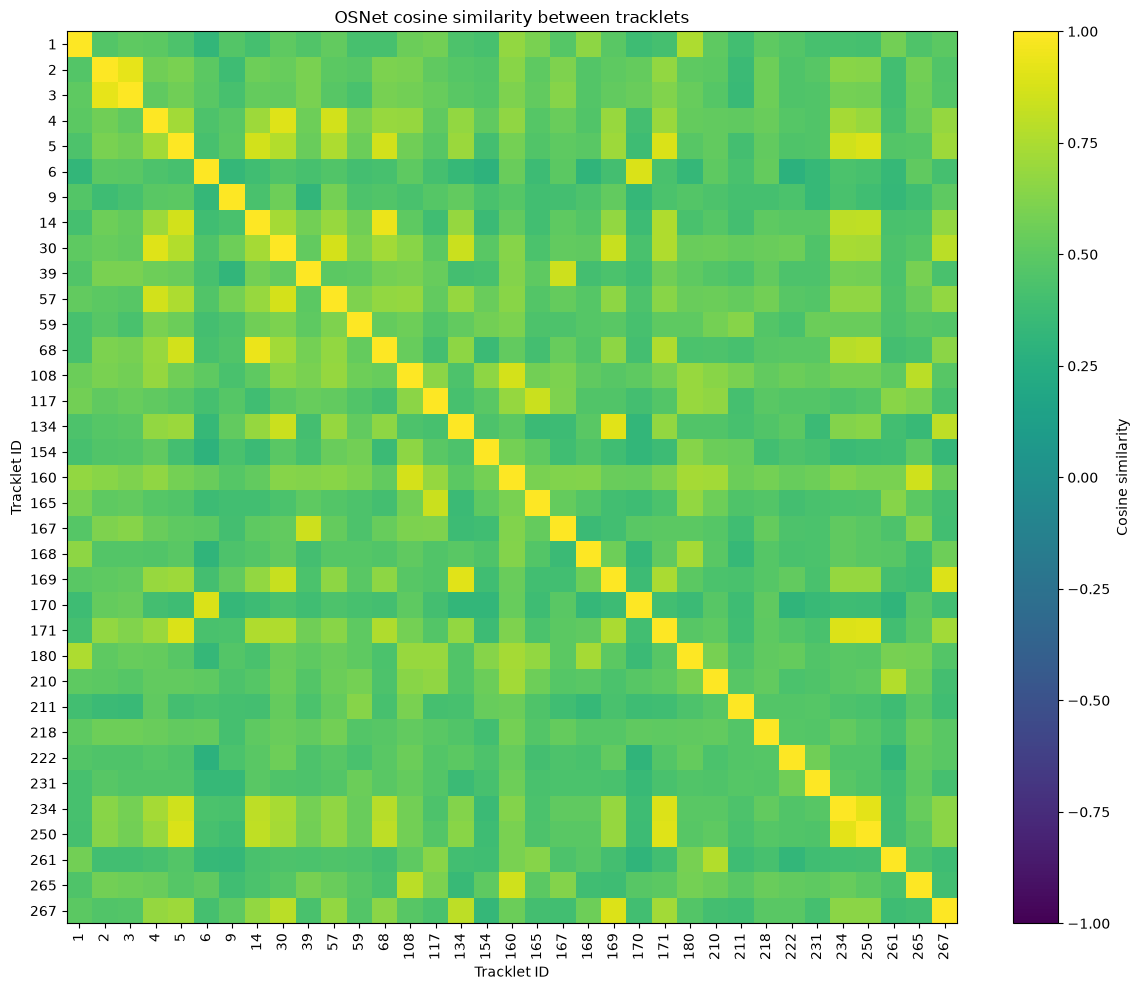

Similarity matrix saved: c:\Users\anyan\source\repos\AeroTrack\outputs\part3_reid\tracklet_similarity_matrix.csv


In [12]:
# Pairwise cosine similarity across all tracklets.
similarity_matrix = tracklet_embeddings @ tracklet_embeddings.T

# Save the similarity matrix with tracker IDs as row/column labels.
similarity_df = pd.DataFrame(
    similarity_matrix,
    index=tracklet_ids,
    columns=tracklet_ids
)

SIMILARITY_PATH = REID_OUTPUT_DIR / "tracklet_similarity_matrix.csv"
similarity_df.to_csv(SIMILARITY_PATH)

plt.figure(figsize=(12, 10))
plt.imshow(similarity_matrix, vmin=-1, vmax=1, aspect="auto")
plt.colorbar(label="Cosine similarity")
plt.xticks(range(len(tracklet_ids)), tracklet_ids, rotation=90)
plt.yticks(range(len(tracklet_ids)), tracklet_ids)
plt.xlabel("Tracklet ID")
plt.ylabel("Tracklet ID")
plt.title("OSNet cosine similarity between tracklets")
plt.tight_layout()
plt.show()

print("Similarity matrix saved:", SIMILARITY_PATH)

## Section 13 — Generate temporally possible match candidates

We compare tracklets that do not overlap in time and whose gap is within the configured maximum.

For each possible pair, the report includes:
- `tracklet_a` and `tracklet_b`
- their cosine similarity
- their cosine distance (`1 - similarity`)
- the time gap between the earlier tracklet ending and the later one starting

The list is ranked by appearance similarity. **It is a review list, not an automatic identity decision.**

In [13]:

# Build exact frame intervals from the tracking log.
frame_intervals = (
    track_log.groupby("track_id")
    .agg(
        first_frame=("frame", "min"),
        last_frame=("frame", "max")
    )
    .reset_index()
)

frame_intervals = frame_intervals[
    frame_intervals["track_id"].isin(tracklet_ids)
]

metadata = (
    tracklet_summary
    .merge(frame_intervals, on="track_id")
    .set_index("track_id")
    .to_dict("index")
)

embedding_index = {
    track_id: index
    for index, track_id in enumerate(tracklet_ids)
}

MAX_REID_GAP_SECONDS = 40

candidate_records = []

for i, track_a in enumerate(tracklet_ids):

    meta_a = metadata[track_a]

    for j in range(i + 1, len(tracklet_ids)):

        track_b = tracklet_ids[j]
        meta_b = metadata[track_b]

        start_a = meta_a["first_frame"]
        end_a = meta_a["last_frame"]

        start_b = meta_b["first_frame"]
        end_b = meta_b["last_frame"]

        # Only compare tracklets that do not overlap in frames.
        if end_a < start_b:
            earlier_id, later_id = track_a, track_b
            gap_frames = start_b - end_a - 1

        elif end_b < start_a:
            earlier_id, later_id = track_b, track_a
            gap_frames = start_a - end_b - 1

        else:
            continue

        gap_seconds = max(0, gap_frames) / SOURCE_FPS

        if gap_seconds > MAX_REID_GAP_SECONDS:
            continue

        similarity = float(
            tracklet_embeddings[embedding_index[track_a]] @
            tracklet_embeddings[embedding_index[track_b]]
        )

        candidate_records.append({
            "tracklet_a": track_a,
            "tracklet_b": track_b,
            "earlier_tracklet": earlier_id,
            "later_tracklet": later_id,
            "gap_frames": gap_frames,
            "gap_seconds": round(gap_seconds, 3),
            "cosine_similarity": round(similarity, 4)
        })

candidate_df = pd.DataFrame(candidate_records)

if not candidate_df.empty:
    candidate_df = candidate_df.sort_values(
        "cosine_similarity",
        ascending=False
    ).reset_index(drop=True)

candidate_df.to_csv(
    REID_OUTPUT_DIR / "candidate_reid_matches.csv",
    index=False
)

display(candidate_df.head(30))


,tracklet_a,tracklet_b,earlier_tracklet,later_tracklet,gap_frames,gap_seconds,cosine_similarity
0,14,68,14,68,7,0.234,0.9396
1,234,250,234,250,19,0.634,0.9169
2,134,169,134,169,37,1.235,0.9097
3,169,267,169,267,16,0.534,0.8929
4,6,170,6,170,35,1.168,0.8884
5,5,250,5,250,464,15.482,0.8877
6,5,171,5,171,37,1.235,0.8838
7,108,160,108,160,52,1.735,0.8692
8,160,265,160,265,96,3.203,0.8539
9,5,234,5,234,435,14.514,0.8535


In [14]:

# Select candidate pairs for manual evaluation.
review_parts = [candidate_df.head(15)]

# Include two useful examples from the crop gallery.
special_pairs = [(1, 180), (39, 167)]

for track_a, track_b in special_pairs:

    pair = candidate_df[
        (
            (candidate_df["tracklet_a"] == track_a) &
            (candidate_df["tracklet_b"] == track_b)
        ) |
        (
            (candidate_df["tracklet_a"] == track_b) &
            (candidate_df["tracklet_b"] == track_a)
        )
    ]

    if not pair.empty:
        review_parts.append(pair)

# Include moderately similar examples as well.
moderate = candidate_df[
    candidate_df["cosine_similarity"].between(0.45, 0.65)
]

if not moderate.empty:
    review_parts.append(
        moderate.sample(
            n=min(8, len(moderate)),
            random_state=42
        )
    )

review_df = (
    pd.concat(review_parts)
    .drop_duplicates(
        subset=["tracklet_a", "tracklet_b"]
    )
    .copy()
)

# Add columns for your manual decisions.
review_df["manual_label"] = ""
review_df["review_notes"] = ""

REVIEW_PATH = REID_OUTPUT_DIR / "reid_manual_review.csv"

review_df.to_csv(REVIEW_PATH, index=False)

print("Pairs selected for review:", len(review_df))
print("Review file:", REVIEW_PATH)

display(
    review_df[
        [
            "tracklet_a",
            "tracklet_b",
            "cosine_similarity",
            "gap_seconds",
            "manual_label"
        ]
    ]
)


Pairs selected for review: 24
Review file: c:\Users\anyan\source\repos\AeroTrack\outputs\part3_reid\reid_manual_review.csv


,tracklet_a,tracklet_b,cosine_similarity,gap_seconds,manual_label
0,14,68,0.9396,0.234,
1,234,250,0.9169,0.634,
2,134,169,0.9097,1.235,
3,169,267,0.8929,0.534,
4,6,170,0.8884,1.168,
5,5,250,0.8877,15.482,
6,5,171,0.8838,1.235,
7,108,160,0.8692,1.735,
8,160,265,0.8539,3.203,
9,5,234,0.8535,14.514,


## Section 14 — Visually review the highest-ranked candidate pairs

This section shows the clearest saved crop for each tracklet in the highest-ranked candidate pairs.

Look for genuinely consistent appearance details such as clothing colour and shape. Do not rely only on similarity score. In overhead footage, different people can look very similar, while the same person can look different when the camera angle or altitude changes.

Review the pair images before approving any global-identity merge.

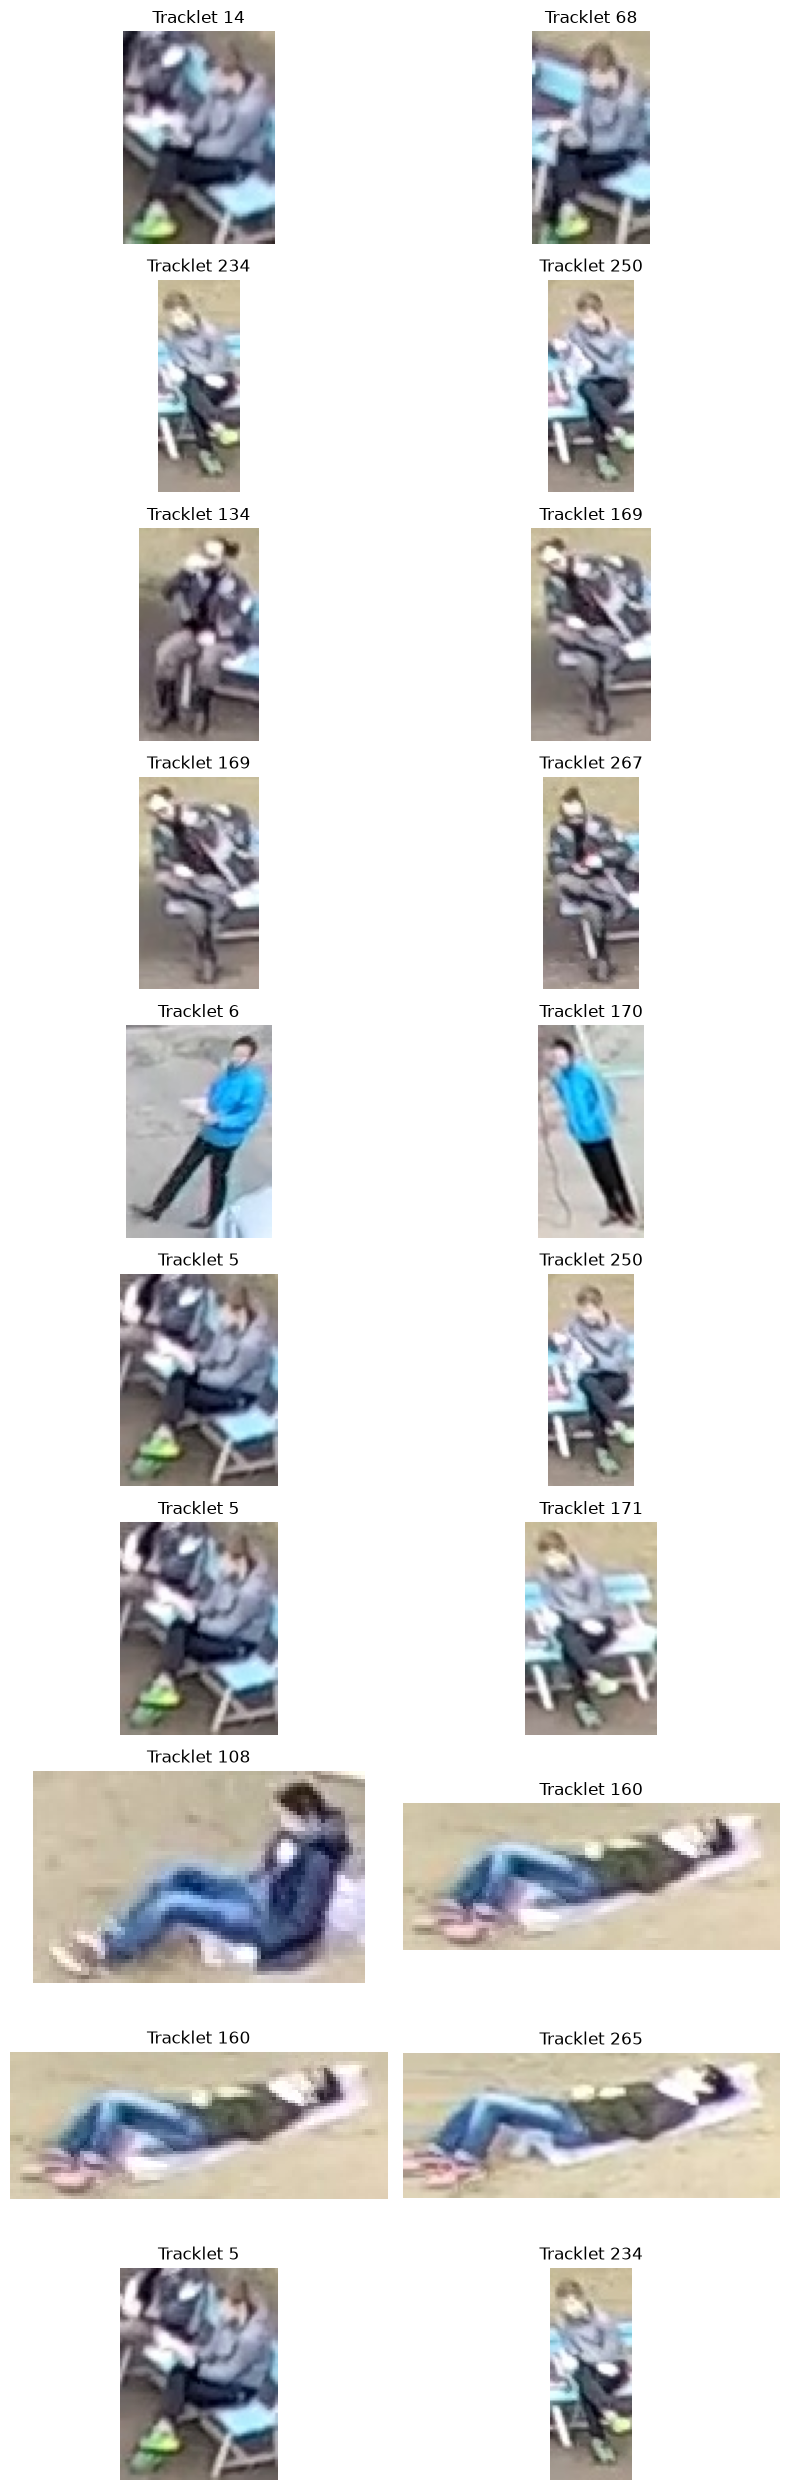

In [15]:
# Find the clearest crop for each tracklet.
representative_paths = (
    crop_manifest
    .sort_values("quality_score", ascending=False)
    .drop_duplicates("track_id")
    .set_index("track_id")["crop_path"]
    .to_dict()
)

def load_rgb_crop(path):
    image = cv2.imread(str(path))
    if image is None:
        return None
    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

NUMBER_OF_PAIRS_TO_REVIEW = 10
pairs_to_review = candidate_df.head(NUMBER_OF_PAIRS_TO_REVIEW)

if pairs_to_review.empty:
    print("No non-overlapping candidate pairs were generated.")
else:
    fig, axes = plt.subplots(
        len(pairs_to_review),
        2,
        figsize=(8, max(3, len(pairs_to_review) * 2.5))
    )

    if len(pairs_to_review) == 1:
        axes = np.array([axes])

    for row_index, (_, pair) in enumerate(pairs_to_review.iterrows()):
        track_a = int(pair["tracklet_a"])
        track_b = int(pair["tracklet_b"])

        image_a = load_rgb_crop(representative_paths[track_a])
        image_b = load_rgb_crop(representative_paths[track_b])

        axes[row_index, 0].axis("off")
        axes[row_index, 1].axis("off")

        if image_a is not None:
            axes[row_index, 0].imshow(image_a)
            axes[row_index, 0].set_title(f"Tracklet {track_a}")

        if image_b is not None:
            axes[row_index, 1].imshow(image_b)
            axes[row_index, 1].set_title(f"Tracklet {track_b}")

        axes[row_index, 0].set_ylabel(
            f"Similarity: {pair['cosine_similarity']:.3f}\n"
            f"Gap: {pair['gap_seconds']:.2f}s",
            rotation=0,
            labelpad=65,
            va="center"
        )

    plt.tight_layout()
    plt.show()

## Section 15 — Create a provisional global identity registry

AeroTrack's global identity layer must remain separate from BoT-SORT's tracker IDs.

For now, identity links are approved manually after reviewing the candidate pairs. Add only pairs you have visually checked and believe show the same individual.

Example syntax:

```python
APPROVED_MATCHES = [
    (1, 14),   # only if you have reviewed and confirmed the pair
    (14, 39)
]
```

Leave the list empty until you have reviewed the crops. The notebook then creates a provisional global ID for every separate tracklet.

This deliberately avoids false identity merges from an uncalibrated OSNet model.

In [16]:
# Add only pairs you have personally reviewed and confirmed.
# Example: [(tracklet_id_a, tracklet_id_b), (tracklet_id_c, tracklet_id_d)]
APPROVED_MATCHES = []

# Build identity groups using a simple union-find structure.
parent = {track_id: track_id for track_id in tracklet_ids}

def find_root(track_id):
    while parent[track_id] != track_id:
        parent[track_id] = parent[parent[track_id]]
        track_id = parent[track_id]
    return track_id

def merge_tracklets(track_a, track_b):
    if track_a not in parent or track_b not in parent:
        raise ValueError(
            f"Tracklet {track_a} or {track_b} has no usable crop/embedding."
        )

    root_a = find_root(track_a)
    root_b = find_root(track_b)

    if root_a != root_b:
        parent[root_b] = root_a

# Merge manually approved pairs.
for track_a, track_b in APPROVED_MATCHES:
    merge_tracklets(int(track_a), int(track_b))

# Assign global IDs in order of first appearance.
ordered_tracklets = tracklet_summary.sort_values(
    "first_seen"
)["track_id"].astype(int).tolist()

root_to_global_id = {}

for track_id in ordered_tracklets:
    root = find_root(track_id)

    if root not in root_to_global_id:
        root_to_global_id[root] = f"G{len(root_to_global_id) + 1:03d}"

registry_rows = []

for track_id in ordered_tracklets:
    root = find_root(track_id)
    members = [
        item for item in ordered_tracklets
        if find_root(item) == root
    ]

    meta = metadata_by_id[track_id]

    registry_rows.append({
        "global_id": root_to_global_id[root],
        "track_id": track_id,
        "first_seen": meta["first_seen"],
        "last_seen": meta["last_seen"],
        "frames_observed": meta["frames_observed"],
        "crop_samples": meta["crop_samples"],
        "identity_status": (
            "manually_merged"
            if len(members) > 1
            else "unmerged_tracklet"
        ),
        "merged_tracklet_count": len(members)
    })

global_registry = pd.DataFrame(registry_rows)

REGISTRY_PATH = REID_OUTPUT_DIR / "provisional_global_identity_registry.csv"
global_registry.to_csv(REGISTRY_PATH, index=False)

print("Tracklets represented:", len(tracklet_ids))
print("Provisional global identities:", global_registry["global_id"].nunique())
print("Manually approved matches:", len(APPROVED_MATCHES))
print("Registry saved:", REGISTRY_PATH)

display(global_registry)

NameError: name 'metadata_by_id' is not defined

## Section 16 — Part 3 outputs and interpretation

The notebook saves:

| Output | Purpose |
|---|---|
| `tracklet_crops/` | Representative person crops grouped by tracker ID |
| `crop_manifest.csv` | Crop path, source frame, time, confidence and dimensions |
| `tracklet_embeddings.npz` | OSNet embedding matrix and corresponding tracklet IDs |
| `tracklet_embedding_summary.csv` | Tracklet time ranges and crop counts |
| `tracklet_similarity_matrix.csv` | Cosine similarity between every pair of tracklets |
| `candidate_reid_matches.csv` | High-similarity pairs that also satisfy the temporal non-overlap rule |
| `provisional_global_identity_registry.csv` | Tracklet-to-global-ID mapping after manual approvals |

## How to interpret this experiment

- If two visually similar tracklets also have high cosine similarity, OSNet may be capturing useful appearance information.
- If different people have high similarity, OSNet is not sufficiently discriminative for those crops.
- If the same person has low similarity across two tracklets, the aerial viewpoint or low crop resolution may be hurting the representation.
- Do not choose a universal cosine threshold from this one clip. We need manually labelled same-person and different-person examples to calibrate it.

## What Part 3 has and has not achieved

**Achieved:** OSNet embeddings have been extracted from the tracklets, and likely cross-tracklet matches have been ranked for review.

**Not yet achieved:** Fully automatic and validated global identity assignment. That requires ground-truth identity pairs and calibration, and may require fine-tuning on an aerial ReID dataset such as PRAI-1581 or P-DESTRE.

The next step is to review the crop gallery and top candidate pairs. We can then measure how often the correct returning person appears among OSNet's top matches before enabling any automatic identity merges.